<a href="https://colab.research.google.com/github/tasosquantumcomputing/Logistic-Regression-Classification/blob/main/Logistic_Regression_Classification_Breast_Cancer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


## Task 1 — Dataset Loading & Initial EDA

**Goal:** Explore and understand the dataset.

### 1. Load Dataset
- Load `load_breast_cancer()` from sklearn.
- Create a DataFrame with features and target.

### 2. Dataset Overview
- Display shape, first 5 rows, and data types.
- Check for missing values and duplicates.

### 3. Target Analysis
- Identify classes 0 and 1.
- Calculate class counts and percentages.
- Visualize class distribution using a countplot.

### 4. Basic Statistics
- Display descriptive statistics.
- Find the 3 features with the highest standard deviation.

### Questions
1. Is the dataset balanced?
2. Why is feature scaling important for Logistic Regression?


In [55]:
from sklearn.datasets import load_breast_cancer
import pandas as pd

In [56]:
bc = load_breast_cancer()

In [57]:
bc.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])

In [58]:
bc.data.shape

(569, 30)

In [59]:
bc.feature_names

array(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error',
       'fractal dimension error', 'worst radius', 'worst texture',
       'worst perimeter', 'worst area', 'worst smoothness',
       'worst compactness', 'worst concavity', 'worst concave points',
       'worst symmetry', 'worst fractal dimension'], dtype='<U23')

In [60]:
bc.target_names

array(['malignant', 'benign'], dtype='<U9')

In [61]:
bc.target.shape

(569,)

In [62]:
df = pd.DataFrame(bc.data,columns = bc.feature_names)

In [63]:
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [64]:
df.shape[0]

569

In [65]:
df.shape[1]

30

In [66]:
df['target'] = bc.target

In [67]:
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [68]:
df.isnull().sum()

,0
mean radius,0
mean texture,0
mean perimeter,0
mean area,0
mean smoothness,0
mean compactness,0
mean concavity,0
mean concave points,0
mean symmetry,0
mean fractal dimension,0


In [69]:
df['target'].value_counts()

,count
target,
1,357
0,212


In [70]:
class0 = df['target'].value_counts()[0] / (df['target'].value_counts()[0] + df['target'].value_counts()[1])

In [71]:
class1 = df['target'].value_counts()[1] / (df['target'].value_counts()[0] + df['target'].value_counts()[1])

In [72]:
class0

np.float64(0.37258347978910367)

In [73]:
class1

np.float64(0.6274165202108963)

In [74]:
classes = {"maligant":class0, "benign":class1}

In [75]:
import matplotlib.pyplot as plt


<BarContainer object of 2 artists>

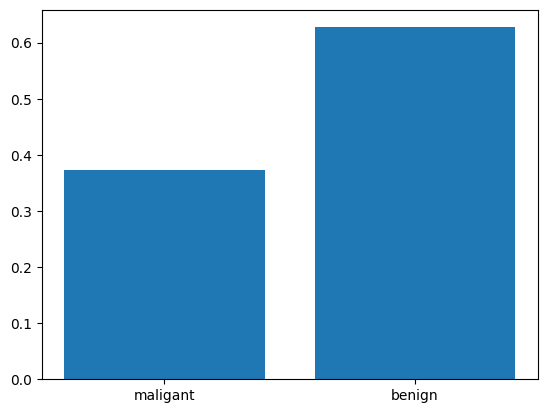

In [76]:
plt.bar(classes.keys(),classes.values())

In [77]:
df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


In [78]:
df.describe().iloc[2]

,std
mean radius,3.524049
mean texture,4.301036
mean perimeter,24.298981
mean area,351.914129
mean smoothness,0.014064
mean compactness,0.052813
mean concavity,0.079720
mean concave points,0.038803
mean symmetry,0.027414
mean fractal dimension,0.007060


In [79]:
df.describe().iloc[2].sort_values(ascending = False)

,std
worst area,569.356993
mean area,351.914129
area error,45.491006
worst perimeter,33.602542
mean perimeter,24.298981
worst texture,6.146258
worst radius,4.833242
mean texture,4.301036
mean radius,3.524049
perimeter error,2.021855



### Questions

**1. Is the dataset balanced?**

The dataset is moderately imbalanced:
- Class 0 (Malignant): 37.3%
- Class 1 (Benign): 62.7%

The imbalance is not severe, but we should consider it when evaluating the model using metrics such as precision, recall, and F1-score.

**2. Why is feature scaling important for Logistic Regression?**

Feature scaling ensures that all features have a comparable scale.

It is important because:
- Features have different numerical ranges.
- It helps the optimization algorithm converge faster.
- It allows regularization to affect features more fairly.

We will use `StandardScaler` to standardize the features.



## Task 2 — Train/Test Split & Feature Scaling

**Goal:** Prepare the dataset for Logistic Regression without data leakage.

### 1. Features & Target
- Separate features (`X`) and target (`y`).
- Check their shapes.

### 2. Train/Test Split
- Split the data into 80% training and 20% testing.
- Use `random_state=42` and `stratify=y`.
- Verify class distribution in both sets.

### 3. Feature Scaling
- Initialize a `StandardScaler`.
- Fit the scaler only on the training data.
- Transform both training and testing data.

### 4. Verification
- Check the mean and standard deviation of the scaled training features.
- Compare feature values before and after scaling.

### Questions
1. Why do we use `stratify=y`?
2. Why should we fit the scaler only on training data?
3. Why don't we scale the target variable?


In [80]:
X = df.drop('target',axis = 1)
y = df['target']

In [81]:
from sklearn.model_selection import train_test_split

In [82]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [83]:
class_distribution = pd.DataFrame({
    "Original (%)": y.value_counts(normalize=True).sort_index() * 100,
    "Train (%)": y_train.value_counts(normalize=True).sort_index() * 100,
    "Test (%)": y_test.value_counts(normalize=True).sort_index() * 100
})

display(class_distribution.round(2))

,Original (%),Train (%),Test (%)
target,,,
0,37.26,37.36,36.84
1,62.74,62.64,63.16


In [84]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [85]:
from sklearn.linear_model import LogisticRegression

In [86]:
model_logistic_regression = LogisticRegression(random_state=42)

In [87]:
pipe_logistic_regression = Pipeline([
    ("scaler", StandardScaler()),
    ("model", model_logistic_regression)
])


## Task 3 — Logistic Regression Training & Predictions

**Goal:** Train the Logistic Regression model and generate predictions.

### 1. Model Training
- Fit the existing pipeline on the training data.
- Verify that the model has been trained successfully.

### 2. Predictions
- Predict the classes for the test set.
- Calculate predicted probabilities using `predict_proba()`.
- Display the first 10 actual vs predicted labels.

### 3. Probability Analysis
- Display the predicted probabilities for the first 5 samples.
- Verify that probabilities for each sample sum to 1.
- Compare predicted classes with a probability threshold of 0.5.

### 4. Model Inspection
- Extract the model's coefficients and intercept.
- Check the shape of the coefficients.

### Questions
1. What is the difference between `predict()` and `predict_proba()`?
2. What does a coefficient's sign indicate?
3. How does the 0.5 decision threshold affect predictions?


In [88]:
pipe_logistic_regression.fit(X_train,y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('model', LogisticRegression(random_state=42))])

In [89]:
y_pred = pipe_logistic_regression.predict(X_test)

In [90]:
# Predict probabilities
y_proba = pipe_logistic_regression.predict_proba(X_test)

# Compare actual and predicted labels
results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred,
    "P(Class 0)": y_proba[:, 0],
    "P(Class 1)": y_proba[:, 1]
})

display(results.head(10))

,Actual,Predicted,P(Class 0),P(Class 1)
0,0,0,1.000000,5.888242e-08
1,1,1,0.000011,9.999887e-01
2,0,0,0.993589,6.410825e-03
3,1,1,0.466491,5.335085e-01
4,0,0,1.000000,6.525001e-10
5,1,1,0.007840,9.921604e-01
6,1,1,0.000017,9.999828e-01
7,0,0,0.999999,5.635275e-07
8,0,0,0.999946,5.431637e-05
9,0,0,1.000000,8.041849e-11


In [92]:
import numpy as np

In [93]:
# Display first 5 probability predictions
print(y_proba[:5])

# Verify probabilities sum to 1
print("Probability sums:", y_proba[:5].sum(axis=1))

# Compare predictions using threshold = 0.5
y_pred_threshold = (y_proba[:, 1] >= 0.5).astype(int)

print("Predictions match:", np.array_equal(y_pred, y_pred_threshold))

[[9.99999941e-01 5.88824186e-08]
 [1.13351672e-05 9.99988665e-01]
 [9.93589175e-01 6.41082462e-03]
 [4.66491463e-01 5.33508537e-01]
 [9.99999999e-01 6.52500097e-10]]
Probability sums: [1. 1. 1. 1. 1.]
Predictions match: True


In [94]:
# Extract trained Logistic Regression model
model = pipe_logistic_regression.named_steps["model"]

# Coefficients and intercept
coefficients = model.coef_
intercept = model.intercept_

print("Coefficients shape:", coefficients.shape)
print("Intercept:", intercept)

# Display coefficients
coef_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": coefficients[0]
})

display(coef_df)

Coefficients shape: (1, 30)
Intercept: [0.30220757]


,Feature,Coefficient
0,mean radius,-0.511479
1,mean texture,-0.552698
2,mean perimeter,-0.476298
3,mean area,-0.541059
4,mean smoothness,-0.212479
5,mean compactness,0.648342
6,mean concavity,-0.602103
7,mean concave points,-0.704156
8,mean symmetry,-0.167233
9,mean fractal dimension,0.199732



### Questions

**1. What is the difference between `predict()` and `predict_proba()`?**

- `predict()` returns the predicted class label (0 or 1).
- `predict_proba()` returns the estimated probability of each class.

**2. What does a coefficient's sign indicate?**

- A positive coefficient increases the log-odds of Class 1 (Benign), holding other features constant.
- A negative coefficient decreases the log-odds of Class 1.

The magnitude indicates the effect per unit increase in the feature, on the model's input scale.

**3. How does the 0.5 decision threshold affect predictions?**

- If P(Class 1) >= 0.5, predict Class 1.
- Otherwise, predict Class 0.

Changing the threshold affects the balance between false positives and false negatives.



## Task 4 — Model Evaluation

**Goal:** Evaluate the Logistic Regression model using classification metrics.

### 1. Classification Metrics
- Calculate accuracy, precision, recall, and F1-score.
- Display a classification report.
- Use macro and weighted averages to compare performance.

### 2. Confusion Matrix
- Calculate and visualize the confusion matrix.
- Identify TP, TN, FP, and FN, treating Malignant (Class 0) as the positive class.

### 3. ROC Curve & AUC
- Calculate ROC-AUC using predicted probabilities.
- Plot the ROC curve.
- Use Malignant (Class 0) as the positive class.

### 4. Error Analysis
- Count the misclassified samples.
- Calculate the misclassification rate.
- Examine the actual and predicted labels of incorrect predictions.

### Questions
1. Why is accuracy alone not enough to evaluate this model?
2. What is the difference between precision and recall?
3. Which error is more critical in this dataset: false positive or false negative, when Malignant is the positive class?
4. What does ROC-AUC measure?


In [95]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, roc_curve, roc_auc_score

In [96]:
classification_report = classification_report(y_test, y_pred)
print(classification_report)


              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [97]:
confusion_matrix = confusion_matrix(y_test, y_pred)
print(confusion_matrix)

[[41  1]
 [ 1 71]]


In [98]:
roc_auc_score = roc_auc_score(y_test, y_proba[:, 1])
print(roc_auc_score)

0.9953703703703703


In [99]:
roc_curve = roc_curve(y_test, y_proba[:, 1])
print(roc_curve)

(array([0.        , 0.        , 0.        , 0.02380952, 0.02380952,
       1.        ]), array([0.        , 0.01388889, 0.80555556, 0.80555556, 1.        ,
       1.        ]), array([           inf, 9.99999580e-01, 9.16588147e-01, 9.08728148e-01,
       3.65861856e-01, 1.63299654e-23]))


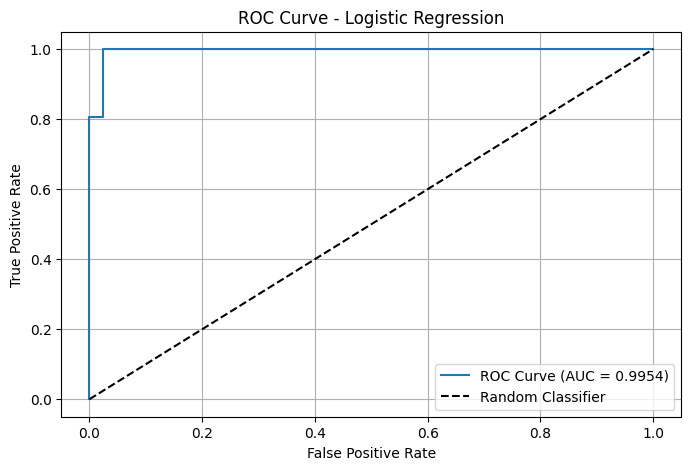

In [102]:
from sklearn.metrics import roc_curve
fpr, tpr, thresholds = roc_curve(y_test, y_proba[:, 1])

plt.figure(figsize=(8, 5))

plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc_score:.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.grid(True)
plt.show()

# Task 5 — Classification Threshold Tuning

## Objective
Understand how changing the classification threshold affects Logistic Regression predictions and evaluation metrics.

## Part 1 — Threshold Comparison

1. Use the predicted probabilities from `predict_proba()`.
2. Test three classification thresholds: `0.3`, `0.5`, and `0.7`.
3. For each threshold, calculate:
   - Accuracy
   - Precision
   - Recall
   - F1-score
   - Confusion Matrix

## Part 2 — Visualization

1. Create a Pandas DataFrame containing the results for each threshold.
2. Plot Precision, Recall, and F1-score against the classification thresholds.
3. Compare how the metrics change as the threshold increases.

## Part 3 — Questions

1. What happens to Recall as the threshold increases?
2. How does changing the threshold affect Precision?
3. Which threshold would you choose to minimize the risk of classifying a malignant tumor as benign?
4. Why is `0.5` not always the optimal classification threshold?

## Important Note

In the Breast Cancer Dataset:
- `0` = Malignant
- `1` = Benign

For this task, keep class `1` as the positive class to ensure consistent metric

In [148]:
compare = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "P(Class 1)": y_proba[:, 1],
    'Predicted with 0.5 thershold': y_pred

})

In [149]:
compare

,Actual,P(Class 1),Predicted with 0.5 thershold
0,0,5.888242e-08,0
1,1,9.999887e-01,1
2,0,6.410825e-03,0
3,1,5.335085e-01,1
4,0,6.525001e-10,0
...,...,...,...
109,0,1.623113e-06,0
110,1,8.520459e-01,1
111,0,6.221233e-04,0
112,1,9.081998e-01,1


In [150]:
compare['Predicted with 0.3 thresholed'] = (compare['P(Class 1)'] >= 0.3).astype(int)
compare['Predicted with 0.7 thresholed'] = (compare['P(Class 1)'] >= 0.7).astype(int)

In [151]:
compare

,Actual,P(Class 1),Predicted with 0.5 thershold,Predicted with 0.3 thresholed,Predicted with 0.7 thresholed
0,0,5.888242e-08,0,0,0
1,1,9.999887e-01,1,1,1
2,0,6.410825e-03,0,0,0
3,1,5.335085e-01,1,1,0
4,0,6.525001e-10,0,0,0
...,...,...,...,...,...
109,0,1.623113e-06,0,0,0
110,1,8.520459e-01,1,1,1
111,0,6.221233e-04,0,0,0
112,1,9.081998e-01,1,1,1


In [152]:
results = []

for i in range(2, 5):
    accuracy = accuracy_score(y_test, compare.iloc[:, i])
    precision = precision_score(y_test, compare.iloc[:, i], pos_label=0)
    recall = recall_score(y_test, compare.iloc[:, i], pos_label=0)
    f1 = f1_score(y_test, compare.iloc[:, i], pos_label=0)

    results.append({
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    })

df_results = pd.DataFrame(results, index=[0.3, 0.5, 0.7])

In [153]:
df_results = pd.DataFrame(results,index = [0.3,0.5,0.7])

In [154]:
df_results

,accuracy,precision,recall,f1
0.3,0.982456,0.976190,0.976190,0.976190
0.5,0.982456,1.000000,0.952381,0.975610
0.7,0.947368,0.891304,0.976190,0.931818


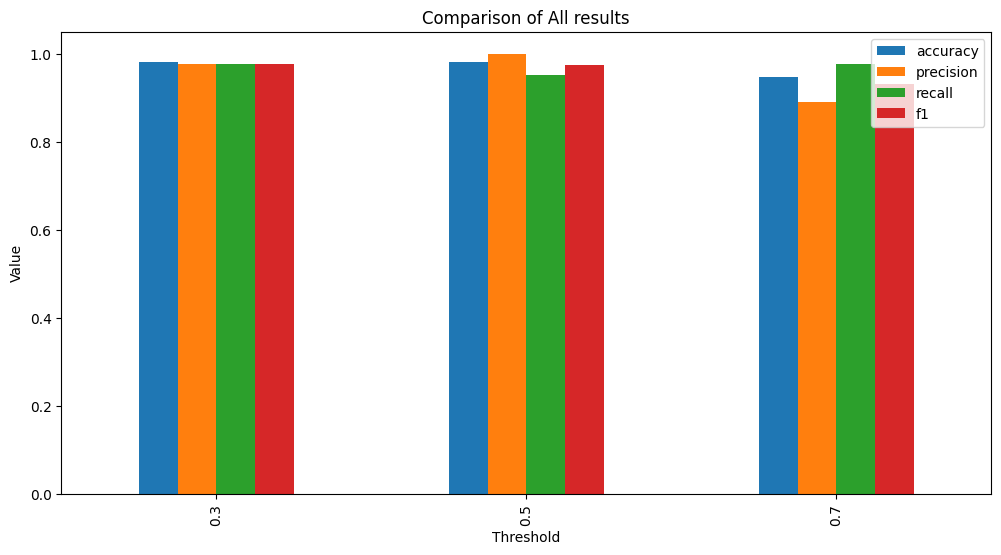

In [155]:
import matplotlib.pyplot as plt

df_results.plot(kind='bar', figsize=(12, 6))

plt.xlabel('Threshold')
plt.ylabel('Value')
plt.title('Comparison of All results')
plt.legend()
plt.show()


### Decision Threshold Analysis

In breast cancer classification, detecting malignant tumors is particularly important.

A higher recall for the malignant class reduces the number of missed malignant cases (false negatives).

Therefore, a model with slightly lower accuracy may be preferable if it achieves higher malignant recall while maintaining acceptable precision.

The decision threshold should be selected using validation data and the costs of different classification errors, rather than accuracy alone.



## Task 5 — Validation-Based Threshold Optimization

**Goal:** Optimize the decision threshold using validation data without test-set leakage.

### 1. Train / Validation / Test Split
- Keep the existing test set (20%) untouched.
- Split the original training set into training (75%) and validation (25%).
- Use `stratify=y_train` and `random_state=42`.

### 2. Model Training
- Create a fresh Logistic Regression pipeline with StandardScaler.
- Train the model on the new training subset.
- Generate predicted probabilities for the validation set.

### 3. Threshold Evaluation
- Evaluate thresholds from 0.1 to 0.9.
- Calculate precision, recall, and F1-score for Malignant (Class 0).
- Visualize the metrics across different thresholds.

### 4. Optimal Threshold Selection
- Select the threshold with the highest malignant recall, subject to precision >= 0.90.
- Break ties using the highest malignant F1-score.
- Report if no threshold satisfies the constraint.

### 5. Final Model Evaluation
- Retrain the pipeline on the full original training set (80%).
- Evaluate the selected threshold on the untouched test set.
- Compare against the default threshold (0.5).

### Questions
1. Why should we avoid optimizing thresholds on the test set?
2. Why do we retrain the model on the full training set?
3. Can the optimal validation threshold perform worse on test data?


In [156]:
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    random_state=42,
    stratify=y_train
)

# Verify dataset shapes
print("Training:", X_train_sub.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (341, 30)
Validation: (114, 30)
Testing: (114, 30)


In [157]:
pipeline_val = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

# Train on training subset
pipeline_val.fit(X_train_sub, y_train_sub)

# Predict validation probabilities
val_proba = pipeline_val.predict_proba(X_val)

# Probability of Class 1 (Benign)
val_proba_class1 = val_proba[:, 1]

In [158]:
thresholds = np.round(np.arange(0.1, 0.91, 0.05), 2)

results = []

for threshold in thresholds:

    y_pred_val = (val_proba_class1 >= threshold).astype(int)

    results.append({
        "threshold": threshold,
        "precision": precision_score(y_val, y_pred_val, pos_label=0),
        "recall": recall_score(y_val, y_pred_val, pos_label=0),
        "f1": f1_score(y_val, y_pred_val, pos_label=0)
    })

df_thresholds = pd.DataFrame(results)

display(df_thresholds)

,threshold,precision,recall,f1
0,0.10,1.000000,0.813953,0.897436
1,0.15,1.000000,0.860465,0.925000
2,0.20,1.000000,0.930233,0.963855
3,0.25,1.000000,0.930233,0.963855
4,0.30,1.000000,0.930233,0.963855
5,0.35,1.000000,0.953488,0.976190
6,0.40,1.000000,0.953488,0.976190
7,0.45,1.000000,0.976744,0.988235
8,0.50,1.000000,0.976744,0.988235
9,0.55,0.954545,0.976744,0.965517


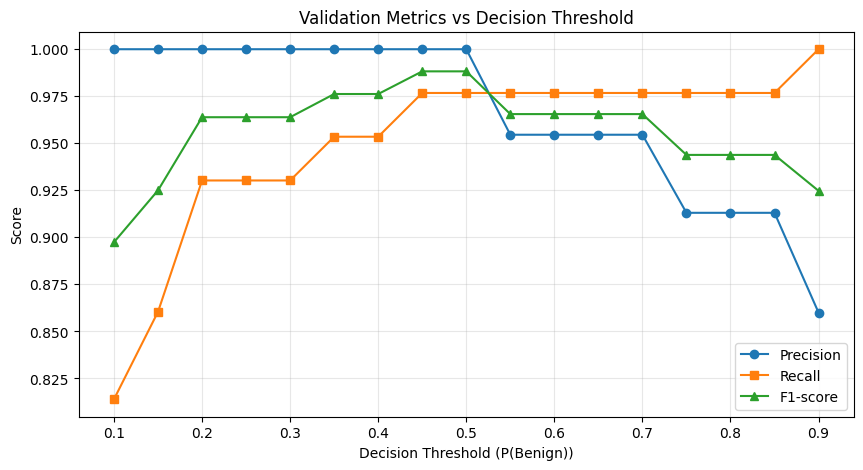

In [159]:
plt.figure(figsize=(10, 5))

plt.plot(df_thresholds["threshold"], df_thresholds["precision"],
         marker="o", label="Precision")

plt.plot(df_thresholds["threshold"], df_thresholds["recall"],
         marker="s", label="Recall")

plt.plot(df_thresholds["threshold"], df_thresholds["f1"],
         marker="^", label="F1-score")

plt.xlabel("Decision Threshold (P(Benign))")
plt.ylabel("Score")
plt.title("Validation Metrics vs Decision Threshold")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [160]:
# Filter thresholds satisfying precision constraint
valid_thresholds = df_thresholds[
    df_thresholds["precision"] >= 0.90
]

if not valid_thresholds.empty:

    best_result = valid_thresholds.sort_values(
        by=["recall", "f1"],
        ascending=[False, False]
    ).iloc[0]

    best_threshold = float(best_result["threshold"])

    print("Optimal Threshold:", best_threshold)
    print("Validation Precision:", best_result["precision"])
    print("Validation Recall:", best_result["recall"])
    print("Validation F1:", best_result["f1"])

else:
    best_threshold = None
    print("No threshold satisfies the precision constraint.")

Optimal Threshold: 0.45
Validation Precision: 1.0
Validation Recall: 0.9767441860465116
Validation F1: 0.9882352941176471


In [162]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

if best_threshold is not None:

    final_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ])

    # Retrain on full training set
    final_pipeline.fit(X_train, y_train)

    # Test probabilities
    test_proba_class1 = final_pipeline.predict_proba(X_test)[:, 1]

    # Predictions using default and optimized thresholds
    y_pred_default = (test_proba_class1 >= 0.5).astype(int)
    y_pred_optimized = (test_proba_class1 >= best_threshold).astype(int)

    # Compare metrics
    comparison = []

    for name, predictions in [
        ("Default (0.5)", y_pred_default),
        ("Optimized", y_pred_optimized)
    ]:
        comparison.append({
            "Model": name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(y_test, predictions, pos_label=0),
            "Recall": recall_score(y_test, predictions, pos_label=0),
            "F1": f1_score(y_test, predictions, pos_label=0)
        })

    df_comparison = pd.DataFrame(comparison).set_index("Model")
    display(df_comparison)

else:
    print("Final evaluation skipped: no valid threshold selected.")

,Accuracy,Precision,Recall,F1
Model,,,,
Default (0.5),0.982456,0.97619,0.97619,0.97619
Optimized,0.982456,0.97619,0.97619,0.97619


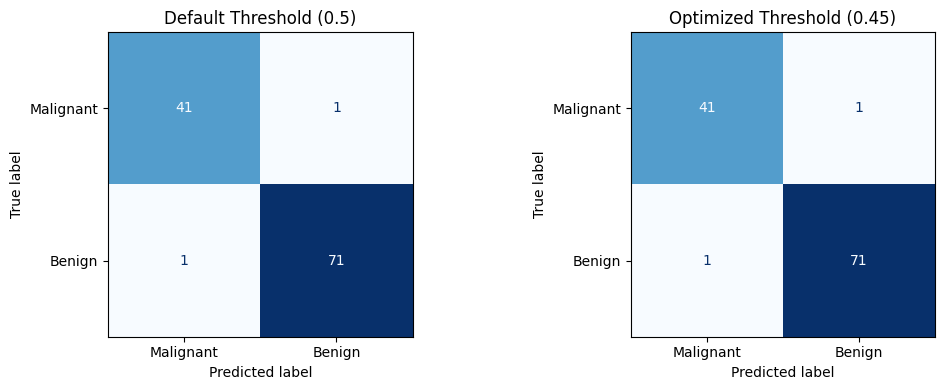

In [163]:
if best_threshold is not None:

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    for ax, predictions, title in zip(
        axes,
        [y_pred_default, y_pred_optimized],
        ["Default Threshold (0.5)", f"Optimized Threshold ({best_threshold:.2f})"]
    ):
        ConfusionMatrixDisplay.from_predictions(
            y_test,
            predictions,
            labels=[0, 1],
            display_labels=["Malignant", "Benign"],
            ax=ax,
            cmap="Blues",
            colorbar=False
        )
        ax.set_title(title)

    plt.tight_layout()
    plt.show()


### Questions

**1. Why should we avoid optimizing thresholds on the test set?**

Optimizing the threshold on the test set causes data leakage from the evaluation stage into model selection.

This can lead to overly optimistic performance estimates because the threshold is selected based on the same data used for final evaluation.

**2. Why do we retrain the model on the full training set?**

Retraining allows the model to learn from more observations by combining the training and validation subsets.

This can improve model generalization and produce more reliable predictions.

**3. Can the selected threshold perform worse on test data?**

Yes. The optimal threshold is selected based on validation data and may not generalize perfectly to unseen test data.

Differences between validation and test performance are expected due to sampling variability.



## Task 6 — Coefficients & Odds Ratios

**Goal:** Interpret how Logistic Regression features influence model predictions.

### 1. Extract Model Coefficients
- Extract coefficients and intercept from the trained pipeline.
- Create a DataFrame containing feature names and coefficients.
- Sort features by absolute coefficient value.

### 2. Feature Importance Visualization
- Select the 10 features with the largest absolute coefficients.
- Create a horizontal bar plot.
- Use different colors for positive and negative coefficients.

### 3. Odds Ratios
- Calculate odds ratios using `np.exp(coefficient)`.
- Add the odds ratios to your DataFrame.
- Identify features with the highest and lowest odds ratios.

### 4. Model Interpretation
- Interpret the signs of positive and negative coefficients.
- Explain what an odds ratio greater than or less than 1 means.
- Discuss how StandardScaler affects coefficient interpretation.

### Questions
1. What does a positive coefficient mean for Class 1 (Benign)?
2. What does an odds ratio of 1.5 indicate?
3. Why should we be careful when interpreting coefficients of highly correlated features?


In [164]:
model = final_pipeline.named_steps["model"]

coefficients = model.coef_[0]
intercept = model.intercept_[0]

In [167]:
coefficients_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": coefficients,
    'Intercept': intercept
})

In [168]:
coefficients_df

,Feature,Coefficient,Intercept
0,mean radius,-0.511479,0.302208
1,mean texture,-0.552698,0.302208
2,mean perimeter,-0.476298,0.302208
3,mean area,-0.541059,0.302208
4,mean smoothness,-0.212479,0.302208
5,mean compactness,0.648342,0.302208
6,mean concavity,-0.602103,0.302208
7,mean concave points,-0.704156,0.302208
8,mean symmetry,-0.167233,0.302208
9,mean fractal dimension,0.199732,0.302208


In [169]:
coefficients_df['abs coefficients'] = coefficients_df['Coefficient'].abs()

In [170]:
coefficients_df

,Feature,Coefficient,Intercept,abs coefficients
0,mean radius,-0.511479,0.302208,0.511479
1,mean texture,-0.552698,0.302208,0.552698
2,mean perimeter,-0.476298,0.302208,0.476298
3,mean area,-0.541059,0.302208,0.541059
4,mean smoothness,-0.212479,0.302208,0.212479
5,mean compactness,0.648342,0.302208,0.648342
6,mean concavity,-0.602103,0.302208,0.602103
7,mean concave points,-0.704156,0.302208,0.704156
8,mean symmetry,-0.167233,0.302208,0.167233
9,mean fractal dimension,0.199732,0.302208,0.199732


In [174]:
coefficients_df = coefficients_df.sort_values(by='abs coefficients', ascending=False)

In [175]:
coefficients_df

,Feature,Coefficient,Intercept,abs coefficients
21,worst texture,-1.255088,0.302208,1.255088
10,radius error,-1.082965,0.302208,1.082965
27,worst concave points,-0.953686,0.302208,0.953686
23,worst area,-0.947756,0.302208,0.947756
20,worst radius,-0.947616,0.302208,0.947616
28,worst symmetry,-0.939181,0.302208,0.939181
13,area error,-0.929104,0.302208,0.929104
26,worst concavity,-0.823151,0.302208,0.823151
22,worst perimeter,-0.763220,0.302208,0.763220
24,worst smoothness,-0.746625,0.302208,0.746625


In [176]:
df_for_plot = coefficients_df.head(10).copy()

In [177]:
df_for_plot

,Feature,Coefficient,Intercept,abs coefficients
21,worst texture,-1.255088,0.302208,1.255088
10,radius error,-1.082965,0.302208,1.082965
27,worst concave points,-0.953686,0.302208,0.953686
23,worst area,-0.947756,0.302208,0.947756
20,worst radius,-0.947616,0.302208,0.947616
28,worst symmetry,-0.939181,0.302208,0.939181
13,area error,-0.929104,0.302208,0.929104
26,worst concavity,-0.823151,0.302208,0.823151
22,worst perimeter,-0.763220,0.302208,0.763220
24,worst smoothness,-0.746625,0.302208,0.746625


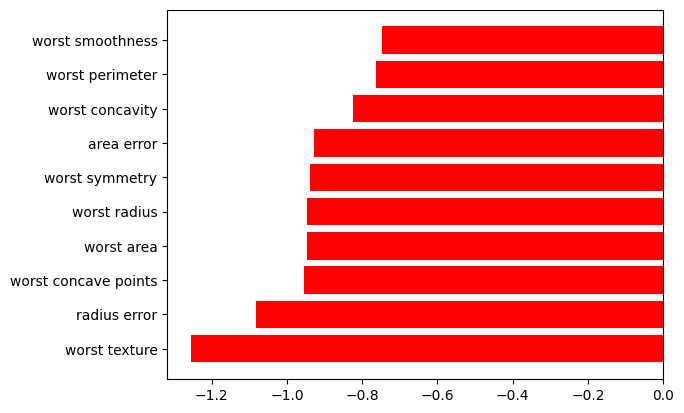

In [178]:
plt.figure()
plt.barh(
    y=df_for_plot["Feature"],
    width=df_for_plot["Coefficient"],
    color=df_for_plot["Coefficient"].apply(lambda x: "red" if x < 0 else "blue")
)
plt.show()

In [179]:
coefficients_df['odds ratios'] = np.exp(coefficients_df['Coefficient'])

In [181]:
coefficients_df

,Feature,Coefficient,Intercept,abs coefficients,odds ratios
21,worst texture,-1.255088,0.302208,1.255088,0.285051
10,radius error,-1.082965,0.302208,1.082965,0.338590
27,worst concave points,-0.953686,0.302208,0.953686,0.385318
23,worst area,-0.947756,0.302208,0.947756,0.387610
20,worst radius,-0.947616,0.302208,0.947616,0.387664
28,worst symmetry,-0.939181,0.302208,0.939181,0.390948
13,area error,-0.929104,0.302208,0.929104,0.394907
26,worst concavity,-0.823151,0.302208,0.823151,0.439046
22,worst perimeter,-0.763220,0.302208,0.763220,0.466163
24,worst smoothness,-0.746625,0.302208,0.746625,0.473964



### 4. Model Interpretation

**Positive and Negative Coefficients**

- Positive coefficients increase the log-odds of Class 1 (Benign).
- Negative coefficients decrease the log-odds of Class 1, favoring Class 0 (Malignant).
- Larger absolute coefficients indicate stronger effects on the log-odds, holding other features constant.

**Odds Ratios**

- OR > 1: The odds of a benign classification increase.
- OR < 1: The odds of a benign classification decrease.
- OR = 1: No change in the odds.

**Impact of StandardScaler**

Since the features are standardized, each coefficient represents the change in log-odds for a one-standard-deviation increase in the corresponding feature, holding other features constant.

This makes coefficient magnitudes more comparable across features.

### Questions

**1. What does a positive coefficient mean for Class 1 (Benign)?**

A positive coefficient means that increasing the corresponding feature increases the log-odds of predicting Class 1 (Benign), assuming all other features remain constant.

**2. What does an odds ratio of 1.5 indicate?**

An odds ratio of 1.5 means that a one-unit increase in the corresponding model input multiplies the odds of Class 1 by 1.5.

This represents a 50% increase in odds, not a 50% increase in probability.

Since we use StandardScaler, one unit corresponds to one standard deviation of the original feature.

**3. Why should we be careful when interpreting coefficients of highly correlated features?**

Highly correlated features contain overlapping information, making it difficult to isolate their individual effects.

This can lead to unstable coefficients, where magnitudes or signs change depending on the other features included in the model.

Therefore, large coefficients do not necessarily indicate greater predictive importance or causality.



## Task 7 — Regularization & Hyperparameter Tuning

**Goal:** Optimize Logistic Regression using regularization and cross-validation.

### 1. Regularization Comparison
- Create Logistic Regression models with L1 and L2 regularization.
- Use `StandardScaler` inside a Pipeline.
- Compare the number of non-zero coefficients for each model.

### 2. Hyperparameter Tuning
- Use `GridSearchCV` with 5-fold Stratified Cross-Validation.
- Test `penalty`: L1 and L2.
- Test `C`: [0.01, 0.1, 1, 10, 100].
- Use a compatible solver (`liblinear`).
- Optimize using ROC-AUC.

### 3. Best Model
- Display the best hyperparameters and cross-validation ROC-AUC.
- Compare the best model's coefficients with the baseline model.
- Visualize the impact of regularization strength on performance.

### 4. Final Evaluation
- Evaluate the best model on the test set.
- Calculate accuracy, malignant precision, recall, F1-score, and ROC-AUC.
- Compare the results against the original Logistic Regression model.

### Questions
1. What is the difference between L1 and L2 regularization?
2. What happens when the parameter `C` decreases?
3. Why is cross-validation useful during hyperparameter tuning?
4. Why should we use a Pipeline inside GridSearchCV?


In [182]:

regularization_results = []

for penalty in ["l1", "l2"]:

    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            penalty=penalty,
            C=1,
            solver="liblinear",
            max_iter=1000,
            random_state=42
        ))
    ])

    pipe.fit(X_train, y_train)

    coefficients = pipe.named_steps["model"].coef_[0]

    regularization_results.append({
        "Penalty": penalty,
        "Non-zero Coefficients": np.count_nonzero(coefficients),
        "Zero Coefficients": np.sum(coefficients == 0),
        "Coefficient L2 Norm": np.linalg.norm(coefficients)
    })

df_regularization = pd.DataFrame(regularization_results)
display(df_regularization)

,Penalty,Non-zero Coefficients,Zero Coefficients,Coefficient L2 Norm
0,l1,16,14,5.032477
1,l2,30,0,3.598427


In [184]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        solver="liblinear",
        max_iter=1000,
        random_state=42
    ))
])

param_grid = {
    "model__penalty": ["l1", "l2"],
    "model__C": [0.01, 0.1, 1, 10, 100]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV ROC-AUC:", grid_search.best_score_)

Best Parameters: {'model__C': 1, 'model__penalty': 'l2'}
Best CV ROC-AUC: 0.9959752321981423


In [185]:
best_model = grid_search.best_estimator_

print("Best Penalty:", grid_search.best_params_["model__penalty"])
print("Best C:", grid_search.best_params_["model__C"])

best_coefficients = best_model.named_steps["model"].coef_[0]

baseline_coefficients = final_pipeline.named_steps["model"].coef_[0]

coef_comparison = pd.DataFrame({
    "Feature": X_train.columns,
    "Baseline": baseline_coefficients,
    "Tuned": best_coefficients
})

coef_comparison["Absolute Difference"] = abs(
    coef_comparison["Baseline"] - coef_comparison["Tuned"]
)

display(
    coef_comparison.sort_values(
        "Absolute Difference",
        ascending=False
    ).head(10)
)

Best Penalty: l2
Best C: 1


,Feature,Baseline,Tuned,Absolute Difference
23,worst area,-0.947756,-0.979282,0.031526
13,area error,-0.929104,-0.958096,0.028992
9,mean fractal dimension,0.199732,0.179213,0.020518
0,mean radius,-0.511479,-0.493112,0.018367
16,concavity error,0.160563,0.177227,0.016665
4,mean smoothness,-0.212479,-0.196100,0.016379
6,mean concavity,-0.602103,-0.618439,0.016336
17,concave points error,-0.443784,-0.428106,0.015678
2,mean perimeter,-0.476298,-0.460988,0.015310
19,fractal dimension error,0.437894,0.423388,0.014506


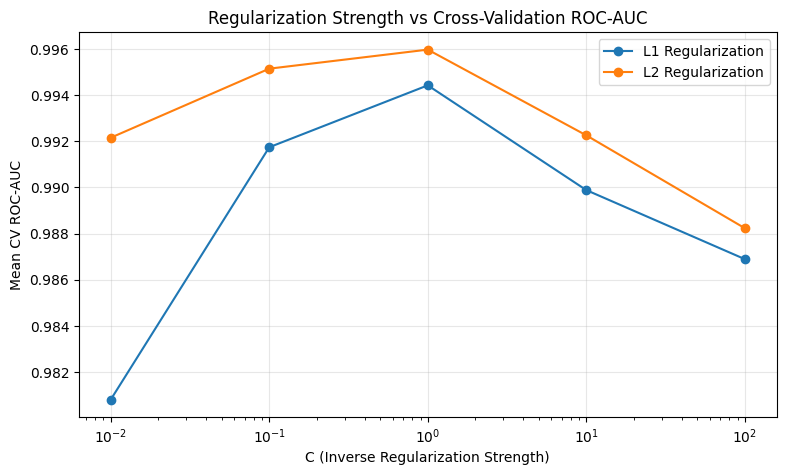

In [186]:
cv_results = pd.DataFrame(grid_search.cv_results_)

cv_results["C"] = cv_results["param_model__C"].astype(float)
cv_results["Penalty"] = cv_results["param_model__penalty"]

plt.figure(figsize=(9, 5))

for penalty in ["l1", "l2"]:
    subset = cv_results[cv_results["Penalty"] == penalty]
    subset = subset.sort_values("C")

    plt.plot(
        subset["C"],
        subset["mean_test_score"],
        marker="o",
        label=f"{penalty.upper()} Regularization"
    )

plt.xscale("log")
plt.xlabel("C (Inverse Regularization Strength)")
plt.ylabel("Mean CV ROC-AUC")
plt.title("Regularization Strength vs Cross-Validation ROC-AUC")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [187]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

models = {
    "Baseline Logistic Regression": final_pipeline,
    "Tuned Logistic Regression": best_model
}

evaluation_results = []

for name, model in models.items():

    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 0]

    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label=0),
        "Recall": recall_score(y_test, y_pred, pos_label=0),
        "F1": f1_score(y_test, y_pred, pos_label=0),
        "ROC-AUC": roc_auc_score(
            (y_test == 0).astype(int),
            y_proba
        )
    })

df_evaluation = pd.DataFrame(evaluation_results).set_index("Model")

display(df_evaluation.round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Baseline Logistic Regression,0.9825,0.9762,0.9762,0.9762,0.9954
Tuned Logistic Regression,0.9825,0.9762,0.9762,0.9762,0.9957



### Questions

**1. What is the difference between L1 and L2 regularization?**

- L1 adds a penalty based on the absolute values of the coefficients.
- L2 adds a penalty based on the squared coefficients.
- L1 can reduce some coefficients to exactly zero, performing feature selection.
- L2 generally shrinks coefficients without eliminating features.

**2. What happens when the parameter C decreases?**

The parameter C controls the inverse of regularization strength.

- Smaller C: Stronger regularization.
- Larger C: Weaker regularization.

Stronger regularization reduces model complexity and can help prevent overfitting, but excessive regularization may cause underfitting.

**3. Why is cross-validation useful during hyperparameter tuning?**

Cross-validation evaluates the model on multiple training/validation splits.

It provides a more reliable estimate of model performance than a single validation split and reduces dependence on one particular data partition.

**4. Why should we use a Pipeline inside GridSearchCV?**

A Pipeline ensures that preprocessing is performed correctly within each cross-validation fold.

The StandardScaler is fitted only on the training portion of each fold, preventing data leakage from validation observations.

This results in more reliable hyperparameter evaluation.
